# 08 – AutoML v0.2: ensembles, cohort validation and final comparison

**ML Project – Early Detection of Students at Risk of Dropout** · Week 3

Module owner: **Axel Warot** · Group **AALT** (DIA4): Léo Chen, Adam Gaabi, Timéo Brajon, Axel Warot

## What changes from v0.1 to v0.2
| | v0.1 (week 2) | v0.2 (week 3) |
|---|---|---|
| Models | 6 standard models | + HistGradientBoosting, LightGBM, XGBoost, TabNet, ensembles |
| Evaluation | best config scored on the search folds | nested CV, same outer folds for all models |
| Imbalance | class weights | class weights vs SMOTE vs undersampling |
| Decision | argmax | + dropout threshold tuned inside the training folds |
| Validation | random folds | + leave-one-cohort-out |

In [1]:
import sys,json,time,warnings
warnings.filterwarnings("ignore")
sys.path.insert(0,"../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from features import *
from evaluation import *
pd.set_option("display.width",160)
pd.set_option("display.max_columns",40)
tr=pd.read_csv("../data/processed/train.csv")
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,VotingClassifier,StackingClassifier
from sklearn.model_selection import LeaveOneGroupOut
from lightgbm import LGBMClassifier
bp=json.load(open("../results/best_params.json"))
def members():
    return [("lr",LogisticRegression(max_iter=3000,class_weight="balanced")),
            ("rf",RandomForestClassifier(**bp["Random forest"],random_state=SEED,n_jobs=1)),
            ("lgbm",LGBMClassifier(**bp["LightGBM"],random_state=SEED,n_jobs=1,verbose=-1))]
def pipe(clf,s):
    return Pipeline([("prep",preprocessor(s)),("clf",clf)])
s="B_semester1"
X,y=split_xy(tr,s)
y=encode(y)

## 1. Ensemble learning
- **Soft voting:** average of the probabilities of logistic regression, random forest and LightGBM.
- **Stacking:** a logistic regression learns how to combine their out-of-fold probabilities (internal 5-fold).

Members use the hyperparameters of notebook 05. These were tuned on the whole training set, so ensembles and their members are evaluated here with the **same small optimistic bias**: the comparison between them stays fair.

In [2]:
cands={"LogReg (balanced)":members()[0][1],"Random forest (tuned)":members()[1][1],"LightGBM (tuned)":members()[2][1],
       "Soft voting":VotingClassifier(members(),voting="soft"),
       "Stacking":StackingClassifier(members(),final_estimator=LogisticRegression(max_iter=3000,class_weight="balanced"),stack_method="predict_proba",cv=5,n_jobs=1)}
t=time.perf_counter()
ens=pd.concat([run_folds(sk(pipe(m,s)),X,y,n,s) for n,m in cands.items()])
ens.to_csv("../results/w3_08_ensembles_folds.csv",index=False)
print(f"{time.perf_counter()-t:.0f} s")
summary(ens).round(3)

64 s


macro_f1  macro_f1_std  bal_acc  dropout_recall  enrolled_f1  roc_auc_ovr
scenario    model                                                                                           
B_semester1 Soft voting               0.709         0.027    0.713           0.722        0.527        0.878
            LightGBM (tuned)          0.703         0.028    0.709           0.712        0.519        0.876
            Stacking                  0.697         0.023    0.710           0.705        0.516        0.875
            Random forest (tuned)     0.695         0.028    0.692           0.731        0.489        0.868
            LogReg (balanced)         0.684         0.022    0.692           0.699        0.488        0.863

## 2. Scenarios A, B, C

In [3]:
sc=[]
for sn in SCENARIOS:
    Xs,ys=split_xy(tr,sn);ys=encode(ys)
    for n in ["LogReg (balanced)","Soft voting"]:
        sc.append(run_folds(sk(pipe(cands[n],sn)),Xs,ys,n,sn))
sc=pd.concat(sc)
sc.to_csv("../results/w3_08_scenarios_folds.csv",index=False)
sc.pivot_table(index="scenario",columns="model",values=["macro_f1","dropout_recall"]).round(3)

dropout_recall                      macro_f1            
model        LogReg (balanced) Soft voting LogReg (balanced) Soft voting
scenario                                                                
A_enrollment             0.587       0.613             0.570       0.594
B_semester1              0.699       0.722             0.684       0.709
C_all                    0.733       0.751             0.711       0.733

## 3. Leave-one-cohort-out validation
The 10 combinations of (unemployment, inflation, GDP) identify the enrollment cohort. Each cohort is predicted by a model trained on the 9 others: this simulates the arrival of a new promotion. The macro variables are removed (they would be constant inside the test cohort).

In [4]:
cohort=tr.groupby(["unemployment_rate","inflation_rate","gdp"]).ngroup().to_numpy()
macro=["unemployment_rate","inflation_rate","gdp"]
pre=preprocessor(s);pre.transformers=[(n,t,[c for c in cols if c not in macro]) for n,t,cols in pre.transformers]
loco=[]
for n in ["LogReg (balanced)","LightGBM (tuned)","Soft voting"]:
    p=Pipeline([("prep",pre),("clf",cands[n])])
    loco.append(run_folds(sk(p),X,y,n,"B – cohort out",cv=LeaveOneGroupOut(),groups=cohort))
loco=pd.concat(loco)
loco["cohort size"]=np.tile(np.bincount(cohort),3)
loco.to_csv("../results/w3_08_cohort_folds.csv",index=False)
rnd=ens.groupby("model")["macro_f1"].mean()
pd.DataFrame({"random 5-fold":rnd[["LogReg (balanced)","LightGBM (tuned)","Soft voting"]],"leave-one-cohort-out":loco.groupby("model")["macro_f1"].mean(),"worst cohort":loco.groupby("model")["macro_f1"].min(),"best cohort":loco.groupby("model")["macro_f1"].max()}).round(3)

,random 5-fold,leave-one-cohort-out,worst cohort,best cohort
model,,,,
LightGBM (tuned),0.703,0.683,0.637,0.752
LogReg (balanced),0.684,0.670,0.631,0.728
Soft voting,0.709,0.690,0.642,0.750


## 4. Overfitting control
Train vs. validation macro-F1 on the same outer folds: a large gap means the model memorises the training students.

In [5]:
from sklearn.model_selection import cross_validate
rows=[]
for n in ["LogReg (balanced)","Random forest (tuned)","LightGBM (tuned)","Soft voting"]:
    r=cross_validate(pipe(cands[n],s),X,y,cv=OUTER,scoring="f1_macro",return_train_score=True,n_jobs=-1)
    rows.append({"model":n,"train macro-F1":r["train_score"].mean(),"validation macro-F1":r["test_score"].mean(),"gap":r["train_score"].mean()-r["test_score"].mean()})
pd.DataFrame(rows).set_index("model").round(3)

,train macro-F1,validation macro-F1,gap
model,,,
LogReg (balanced),0.723,0.684,0.039
Random forest (tuned),0.998,0.695,0.302
LightGBM (tuned),0.817,0.703,0.114
Soft voting,0.886,0.709,0.176


The logistic regression barely overfits. The random forest (deep trees, leaves of 1 student) fits the training set almost perfectly, LightGBM much less thanks to its small learning rate, subsampling and L2 penalty. A large train/validation gap is acceptable as long as the validation score, measured on unseen folds, stays the best, which is the case for soft voting; it remains the reason why every model is judged only on validation folds.

## 5. Final comparison – all models of week 3 (scenario B, same outer folds)

In [6]:
allres=pd.concat([pd.read_csv("../results/w3_05_boosting_folds.csv"),pd.read_csv("../results/w3_06_threshold_folds.csv"),pd.read_csv("../results/w3_07_tabnet_folds.csv"),ens.query("model in ['Soft voting','Stacking']")])
allres=allres.query("scenario=='B_semester1' and not model.str.contains('argmax')")
tab=summary(allres,("macro_f1","bal_acc","dropout_recall","dropout_precision","enrolled_f1","roc_auc_ovr")).reset_index(level=0,drop=True)
base=allres.query("model=='Baseline LogReg'").set_index("fold")["macro_f1"]
tab["folds won vs baseline"]=[int((allres.query("model==@m").set_index("fold")["macro_f1"]>base).sum()) if m!="Baseline LogReg" else np.nan for m in tab.index]
tab.to_csv("../results/week3_comparison.csv")
tab.round(3)

,macro_f1,macro_f1_std,bal_acc,dropout_recall,dropout_precision,enrolled_f1,roc_auc_ovr,folds won vs baseline
model,,,,,,,,
Soft voting,0.709,0.027,0.713,0.722,0.822,0.527,0.878,5.0
LightGBM,0.702,0.025,0.706,0.718,0.825,0.513,0.876,5.0
HistGradientBoosting,0.699,0.018,0.702,0.718,0.826,0.503,0.875,4.0
Stacking,0.697,0.023,0.710,0.705,0.834,0.516,0.875,5.0
Random forest,0.688,0.028,0.686,0.715,0.806,0.480,0.867,3.0
Baseline LogReg,0.684,0.022,0.692,0.699,0.809,0.488,0.863,NaN
XGBoost,0.681,0.035,0.672,0.759,0.800,0.423,0.879,3.0
LightGBM + weights (threshold),0.671,0.029,0.675,0.804,0.714,0.439,0.876,1.0
LogReg + weights (threshold),0.664,0.020,0.670,0.820,0.701,0.432,0.863,1.0


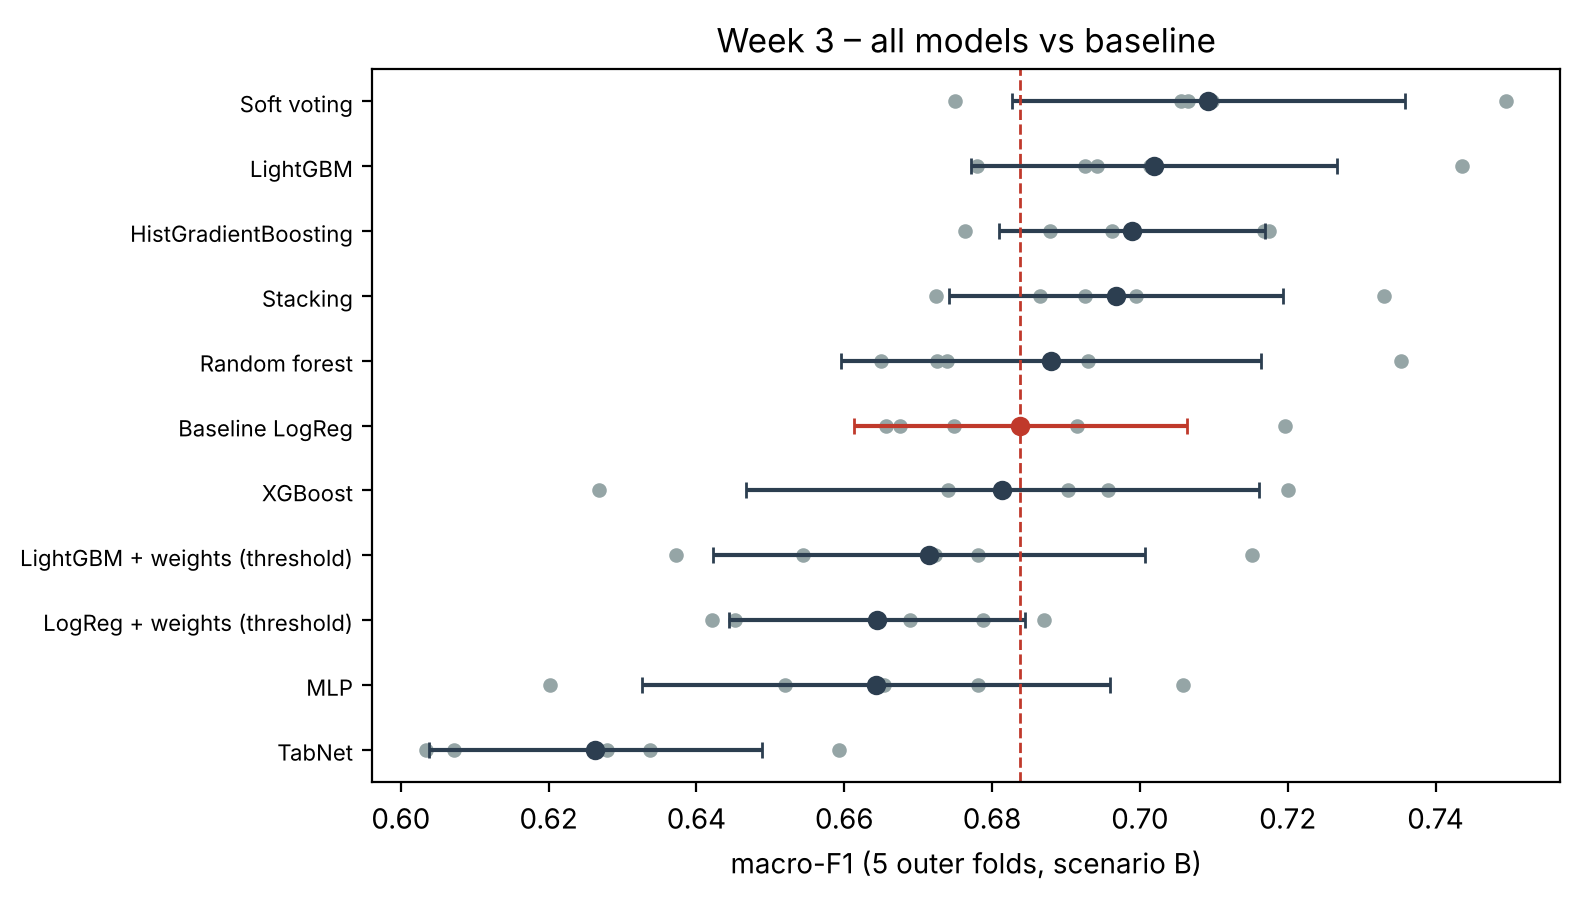

In [7]:
order=tab.index[::-1]
fig,ax=plt.subplots(figsize=(8,4.6))
for i,m in enumerate(order):
    v=allres.query("model==@m")["macro_f1"]
    ax.scatter(v,[i]*len(v),color="#95a5a6",s=18)
    ax.errorbar(v.mean(),i,xerr=v.std(),fmt="o",color="#c0392b" if m=="Baseline LogReg" else "#2c3e50",capsize=3)
ax.set_yticks(range(len(order)),order,fontsize=8);ax.set_xlabel("macro-F1 (5 outer folds, scenario B)")
ax.axvline(base.mean(),ls="--",c="#c0392b",lw=1);ax.set_title("Week 3 – all models vs baseline")
plt.tight_layout();plt.savefig("../report/figures/w3_comparison.png",dpi=150);plt.show()

## Analysis
- **Soft voting** (LogReg + RF + LightGBM) is the best model: macro-F1 **0.709**, +0.025 over the baseline, better on all 5 folds; LightGBM alone is close (0.702–0.703). The gains are about the size of one fold standard deviation (≈ 0.025): real but modest.
- **Stacking** (0.697) is below soft voting: the extra meta-model does not help with 3,539 students.
- **TabNet** (0.626) and the MLP (0.664) do not beat the simpler models on this data size.
- The **threshold** is what changes the business result most: dropout recall goes from ≈ 0.71 to 0.80 (precision 0.82 → 0.71).
- **Leave-one-cohort-out** scores are ≈ 0.02 lower than random folds (soft voting 0.690, cohorts from 0.64 to 0.75): a new cohort is harder to predict, but the ranking of the models does not change.

**Candidate for week 4:** soft voting with class weights and the dropout threshold, compared once with the baseline on the sealed test set.